In [ ]:
# !pip install -U "tensorflow[and-cuda]==2.18.*" tf2onnx 


In [ ]:
# !pip show tensorflow

In [1]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '2'

In [2]:
import tensorflow as tf
print("CUDA_VISIBLE_DEVICES:", os.environ.get("CUDA_VISIBLE_DEVICES"))

2025-12-06 18:53:20.712402: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-12-06 18:53:20.730168: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1765047200.750915     139 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1765047200.756866     139 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-12-06 18:53:20.778351: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

CUDA_VISIBLE_DEVICES: 2


In [3]:
physical = tf.config.list_physical_devices("GPU")
visible  = tf.config.get_visible_devices("GPU")
logical  = tf.config.list_logical_devices("GPU")

print("Physical:", physical)                       # ex.: [PhysicalDevice(name='/physical_device:GPU:0', ...)]
print("Visible :", [d.name for d in visible])      # ex.: ['/physical_device:GPU:0']
print("Logical :", [d.name for d in logical])      # ex.: ['/device:GPU:0']

# Detalhes úteis (nome do modelo, CC)
for d in visible:
    det = tf.config.experimental.get_device_details(d)
    print("Detalhes:", d.name, det.get("device_name"), det.get("compute_capability"))

Physical: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Visible : ['/physical_device:GPU:0']
Logical : ['/device:GPU:0']
Detalhes: /physical_device:GPU:0 NVIDIA H100 80GB HBM3 (9, 0)


I0000 00:00:1765047202.800021     139 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 78764 MB memory:  -> device: 0, name: NVIDIA H100 80GB HBM3, pci bus id: 0000:52:00.0, compute capability: 9.0


# Configuração 

In [4]:
VERSION = "v2_Wolosky_U2Net_Sam3_320x320"

In [5]:
import os, random, csv
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow Version:", tf.__version__)


tf.config.list_physical_devices("GPU")

TensorFlow Version: 2.18.1


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

# Dados

In [6]:
class TrainConfig:
    MANIFEST_CSV="/home/jovyan/arquivos/notebooks_jupyter_vinimw/datasets_folder/SAM3_sky_dataset/dataset_sam3_sky_processed/manifest.csv"
    OUT_DIR = f"/home/jovyan/arquivos/notebooks_jupyter_vinimw/tensorflow/Wolosky_U2Net_Sam3/Pesos_wolosky_sam3/{VERSION}"
    IMG_SIZE = (320, 320)
    BATCH_SIZE = 32
    EPOCHS = 100
    LR = 1e-3
    WEIGHT_DECAY = 1e-4
    SEED = 42
    EARLY_STOP_PATIENCE = 10
    BCE_WEIGHT = 1.0
    DICE_WEIGHT = 1.0

    TRAIN_FRAC = 0.7
    VAL_FRAC   = 0.15
    TEST_FRAC  = 0.15

    VERSION = VERSION
    

os.makedirs(TrainConfig.OUT_DIR, exist_ok=True)
tf.keras.utils.set_random_seed(TrainConfig.SEED)

In [7]:
# ===========================
# 2) Dados 
# ===========================
def _paths_from_manifest(csv_path):
    df = pd.read_csv(csv_path)
    base = Path(csv_path).parent
    img_col = df['original_saved_path'] if 'original_saved_path' in df.columns else df['image_path']
    df['image_full_path'] = img_col.apply(lambda p: str(base / p))
    df['mask_full_path']  = df['mask_path'].apply(lambda p: str(base / p))
    df = df[df['image_full_path'].apply(lambda p: Path(p).exists()) &
            df['mask_full_path'].apply(lambda p: Path(p).exists())]
    return df['image_full_path'].tolist(), df['mask_full_path'].tolist()

def _read_img_mask(img_path, mask_path):
    img = tf.io.decode_image(tf.io.read_file(img_path), channels=3, expand_animations=False)
    img = tf.image.convert_image_dtype(img, tf.float32)  # [0, 1]
    msk = tf.io.decode_image(tf.io.read_file(mask_path), channels=1, expand_animations=False)
    msk = tf.image.convert_image_dtype(msk, tf.float32)  # [0, 1]
    img.set_shape([None, None, 3])
    msk.set_shape([None, None, 1])
    return img, msk

def _resize(img, msk, size):
    img = tf.image.resize(img, size, method="bilinear")
    msk = tf.image.resize(msk, size, method="nearest")
    msk = tf.cast(msk > 0.5, tf.float32) 
    return img, msk


_geom = keras.Sequential([
    layers.RandomFlip(mode="horizontal"),
    layers.RandomRotation(factor=15/360, fill_mode="nearest"),
])

def _augment(img, msk):
    """Augmentações em imagens [0, 1] - ANTES da normalização"""
    # 1. Augmentações fotométricas (brightness/contrast)
    img = tf.image.random_brightness(img, 0.12)
    img = tf.image.random_contrast(img, 0.8, 1.2)
    img = tf.clip_by_value(img, 0.0, 1.0)  # Garantir [0, 1]
    
    # 2. Augmentações geométricas síncronas
    x = tf.concat([img, msk], axis=-1)
    x = _geom(x, training=True)
    img, msk = x[..., :3], x[..., 3:]
    
    return img, msk






In [8]:
SCALES = tf.constant([
    [96, 96],
    [128, 128],
    [256, 256],
    [320, 320],
], dtype=tf.int32)

def _random_resize_batch(imgs, msks):
    idx = tf.random.uniform([], minval=0, maxval=tf.shape(SCALES)[0], dtype=tf.int32)
    size = SCALES[idx]  # [2]
    imgs = tf.image.resize(imgs, size, method="bilinear")
    msks = tf.image.resize(msks, size, method="nearest")
    msks = tf.cast(msks > 0.5, tf.float32)
    return imgs, msks

def make_dataset(img_paths, msk_paths, training: bool):
    ds = tf.data.Dataset.from_tensor_slices((img_paths, msk_paths))

    if training:
        ds = ds.shuffle(buffer_size=len(img_paths),
                        seed=TrainConfig.SEED,
                        reshuffle_each_iteration=True)

    ds = ds.map(lambda ip, mp: _read_img_mask(ip, mp),
                num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        ds = ds.batch(TrainConfig.BATCH_SIZE)
        ds = ds.map(_random_resize_batch,
                    num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(_augment,
                    num_parallel_calls=tf.data.AUTOTUNE)
    else:
        ds = ds.map(lambda i, m: _resize(i, m, TrainConfig.IMG_SIZE),
                    num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.batch(TrainConfig.BATCH_SIZE)

    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


In [9]:
img_paths, msk_paths = _paths_from_manifest(TrainConfig.MANIFEST_CSV)
n = len(img_paths)
idx = np.arange(n)
rng = np.random.default_rng(TrainConfig.SEED)
rng.shuffle(idx)

train_cut = int(TrainConfig.TRAIN_FRAC * n)
val_cut   = int((TrainConfig.TRAIN_FRAC + TrainConfig.VAL_FRAC) * n)

train_idx = idx[:train_cut]
val_idx   = idx[train_cut:val_cut]
test_idx  = idx[val_cut:]

train_ds = make_dataset([img_paths[i] for i in train_idx],
                        [msk_paths[i] for i in train_idx], training=True)

val_ds   = make_dataset([img_paths[i] for i in val_idx],
                        [msk_paths[i] for i in val_idx], training=False)

test_ds  = make_dataset([img_paths[i] for i in test_idx],
                        [msk_paths[i] for i in test_idx], training=False)

# Arquitetura do Modelo e Funções de Perda

In [10]:
# ===========================
# 3) Modelo – LiteU2Net (RSU4F only)
# ===========================
class ConvBlock(layers.Layer):
    def __init__(self, out_ch, dilate=1, name=None):
        super().__init__(name=name)
        self.conv = layers.Conv2D(out_ch, 3, padding="same", dilation_rate=dilate, use_bias=False)
        self.bn = layers.BatchNormalization()
        self.act = layers.ReLU()
    def call(self, x, training=False):
        x = self.conv(x); x = self.bn(x, training=training); return self.act(x)

class RSU4F(layers.Layer):
    def __init__(self, in_ch, mid_ch, out_ch, name=None):
        super().__init__(name=name)
        self.conv_in = ConvBlock(out_ch, dilate=1, name="conv_in")
        self.conv1   = ConvBlock(mid_ch, dilate=1, name="conv1")
        self.conv2   = ConvBlock(mid_ch, dilate=2, name="conv2")
        self.conv3   = ConvBlock(mid_ch, dilate=4, name="conv3")
        self.conv4   = ConvBlock(mid_ch, dilate=8, name="conv4")
        self.conv3d  = ConvBlock(mid_ch, dilate=4, name="conv3d")
        self.conv2d  = ConvBlock(mid_ch, dilate=2, name="conv2d")
        self.conv1d  = ConvBlock(out_ch,  dilate=1, name="conv1d")
        self.concat  = layers.Concatenate(axis=-1)
        self.ups2    = layers.UpSampling2D(size=1, interpolation="bilinear")  # (não usado; RSU4F é sem pooling)

    def call(self, x, training=False):
        x_in = self.conv_in(x, training=training)
        x1 = self.conv1(x_in, training=training)
        x2 = self.conv2(x1,   training=training)
        x3 = self.conv3(x2,   training=training)
        x4 = self.conv4(x3,   training=training)
        x3d = self.conv3d(self.concat([x4, x3]), training=training)
        x2d = self.conv2d(self.concat([x3d, x2]), training=training)
        x1d = self.conv1d(self.concat([x2d, x1]), training=training)
        return layers.Add()([x1d, x_in])

    def build(self, input_shape):
        # Nenhuma variável adicional além das já criadas nos sub-layers
        super().build(input_shape)



In [11]:
def build_lite_u2net_tf(input_channels=3, out_ch=1):
    inp = keras.Input(shape=(None, None, input_channels), name="input")

    hx1 = RSU4F(3, 16, 32, name="stage1")(inp);      p12 = layers.MaxPool2D(2)(hx1)
    hx2 = RSU4F(32, 16, 64, name="stage2")(p12);     p23 = layers.MaxPool2D(2)(hx2)
    hx3 = RSU4F(64, 32, 128, name="stage3")(p23);    p34 = layers.MaxPool2D(2)(hx3)
    hx4 = RSU4F(128, 64, 256, name="stage4")(p34)

    up  = layers.UpSampling2D(size=2, interpolation="bilinear")
    cat = layers.Concatenate(axis=-1)

    hx3d = RSU4F(256 + 128, 32, 128, name="stage3d")(cat([up(hx4), hx3]))
    hx2d = RSU4F(128 + 64, 16, 64, name="stage2d")(cat([up(hx3d), hx2]))
    hx1d = RSU4F(64 + 32, 16, 32, name="stage1d")(cat([up(hx2d), hx1]))

    d1 = layers.Conv2D(out_ch, 3, padding="same", name="side1_logits")(hx1d)
    d2 = layers.Conv2D(out_ch, 3, padding="same", name="side2_logits")(hx2d); d2u = up(d2)
    d3 = layers.Conv2D(out_ch, 3, padding="same", name="side3_logits")(hx3d); d3u = layers.UpSampling2D(size=4, interpolation="bilinear")(d3)
    d4 = layers.Conv2D(out_ch, 3, padding="same", name="side4_logits")(hx4);  d4u = layers.UpSampling2D(size=8, interpolation="bilinear")(d4)

    fuse = layers.Concatenate(name="fuse_concat")([d1, d2u, d3u, d4u])
    d0_logits = layers.Conv2D(out_ch, 1, name="outconv_logits")(fuse)

    d0 = layers.Activation("sigmoid", name="output_fused")(d0_logits)
    o1 = layers.Activation("sigmoid", name="output_d1")(d1)
    o2 = layers.Activation("sigmoid", name="output_d2")(d2u)
    o3 = layers.Activation("sigmoid", name="output_d3")(d3u)
    o4 = layers.Activation("sigmoid", name="output_d4")(d4u)

    return keras.Model(inp, [d0, o1, o2, o3, o4], name="LiteU2NetTF")


In [12]:
# ===========================
# 4) Perdas e Métrica (BCE + Dice), iguais para todas as saídas
# ===========================
def dice_loss_tf(y_true, y_pred, smooth=1e-6):
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])
    inter = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred)
    return 1.0 - (2.0 * inter + smooth) / (union + smooth)

def bce_dice_loss_tf(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    dice = dice_loss_tf(y_true, y_pred)
    return TrainConfig.BCE_WEIGHT * bce + TrainConfig.DICE_WEIGHT * dice

# métrica IoU no d0 (probabilidade)
def iou_metric_tf(y_true, y_pred, thresh=0.5):
    y_pred_bin = tf.cast(y_pred >= thresh, tf.float32)
    inter = tf.reduce_sum(y_true * y_pred_bin)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred_bin) - inter
    return tf.math.divide_no_nan(inter, union)

# replicar alvo para as 5 saídas
def replicate_targets(img, msk):
    return img, (msk, msk, msk, msk, msk)

In [13]:
model = build_lite_u2net_tf(input_channels=3, out_ch=1)
print("Params (M):", model.count_params()/1e6)
model.summary(line_length=160)

Params (M): 2.181193


Model: "LiteU2NetTF"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━
┃ Layer (type)                                  ┃ Output Shape                           ┃                   Param 
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━
│ input (InputLayer)                            │ (None, None, None, 3)                  │                         
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ stage1 (RSU4F)                                │ (None, None, None, 32)                 │                    31,45
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ max_pooling2d (MaxPooling2D)                  │ (None, None, None, 32)                 │                         
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ stage2 (RSU4F)                                │ (None, None, None, 64)                 │                    63,10
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ max_pooling2d_1 (MaxPooling2D)                │ (None, None, None, 64)                 │                         
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ stage3 (RSU4F)                                │ (None, None, None, 128)                │                   250,62
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ max_pooling2d_2 (MaxPooling2D)                │ (None, None, None, 128)                │                         
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ stage4 (RSU4F)                                │ (None, None, None, 256)                │                   998,91
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ up_sampling2d_4 (UpSampling2D)                │ (None, None, None, 1)                  │                         
│                                               │                                        │                         
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ concatenate_4 (Concatenate)                   │ (None, None, None, 96)                 │                         
│                                               │                                        │                         
│                                               │                                        │                         
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ stage3d (RSU4F)                               │ (None, None, None, 128)                │                   619,26
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ stage2d (RSU4F)                               │ (None, None, None, 64)                 │                   155,26
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ stage1d (RSU4F)                               │ (None, None, None, 32)                 │                    58,24
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ side2_logits (Conv2D)                         │ (None, None, None, 1)                  │                       57
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ side3_logits (Conv2D)                         │ (None,

 Total params: 2,181,193 (8.32 MB)

 Trainable params: 2,176,073 (8.30 MB)

 Non-trainable params: 5,120 (20.00 KB)

# Treino

In [14]:
train_ds_sup = train_ds.map(replicate_targets, num_parallel_calls=tf.data.AUTOTUNE)
val_ds_sup   = val_ds.map(replicate_targets,   num_parallel_calls=tf.data.AUTOTUNE)

In [15]:
optimizer = keras.optimizers.AdamW(learning_rate=TrainConfig.LR, weight_decay=TrainConfig.WEIGHT_DECAY)
model.compile(
    optimizer=optimizer,
    loss=[bce_dice_loss_tf]*5,
    metrics=[[iou_metric_tf], [], [], [], []],   # IoU apenas na cabeça d0
)

ckpt_path = str(Path(TrainConfig.OUT_DIR) / f"best_model_{TrainConfig.VERSION}.keras")
callbacks = [
    keras.callbacks.ModelCheckpoint(
        ckpt_path, 
        monitor="val_output_fused_iou_metric_tf",
        save_best_only=True, 
        mode="max", 
        verbose=1
    ),
    
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_output_fused_iou_metric_tf",  
        factor=0.5, 
        patience=3, 
        mode="max",  
        verbose=1,
        min_lr=1e-7 
    ),
    
    keras.callbacks.EarlyStopping(
        monitor="val_output_fused_iou_metric_tf",
        patience=TrainConfig.EARLY_STOP_PATIENCE,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
]

In [16]:
history = model.fit(
    train_ds_sup,
    epochs=TrainConfig.EPOCHS,
    validation_data=val_ds_sup,
    callbacks=callbacks,
    verbose=1
)

2025-12-06 18:56:14.062155: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'input_reduce_transpose_fusion_21', 88 bytes spill stores, 76 bytes spill loads



598/599 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step - loss: 2.0520 - output_d1_loss: 0.3961 - output_d2_loss: 0.3920 - output_d3_loss: 0.4209 - output_d4_loss: 0.4223 - output_fused_iou_metric_tf: 0.7815 - output_fused_loss: 0.4206

E0000 00:00:1765047520.228275     729 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1765047520.366159     729 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-12-06 18:59:24.628620: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'input_reduce_select_fusion_13', 36 bytes spill stores, 36 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'input_reduce_transpose_fusion_19', 200 bytes spill stores, 188 bytes spill loads



599/599 ━━━━━━━━━━━━━━━━━━━━ 0s 359ms/step - loss: 2.0513 - output_d1_loss: 0.3959 - output_d2_loss: 0.3919 - output_d3_loss: 0.4208 - output_d4_loss: 0.4222 - output_fused_iou_metric_tf: 0.7816 - output_fused_loss: 0.4205

E0000 00:00:1765047580.679401     727 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1765047580.812929     727 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_output_fused_iou_metric_tf improved from -inf to 0.88250, saving model to /home/jovyan/arquivos/notebooks_jupyter_vinimw/tensorflow/Wolosky_U2Net_Sam3/Pesos_wolosky_sam3/v2_Wolosky_U2Net_Sam3_320x320/best_model_v2_Wolosky_U2Net_Sam3_320x320.keras
599/599 ━━━━━━━━━━━━━━━━━━━━ 333s 392ms/step - loss: 2.0506 - output_d1_loss: 0.3958 - output_d2_loss: 0.3917 - output_d3_loss: 0.4207 - output_d4_loss: 0.4221 - output_fused_iou_metric_tf: 0.7817 - output_fused_loss: 0.4203 - val_loss: 1.2512 - val_output_d1_loss: 0.2572 - val_output_d2_loss: 0.2498 - val_output_d3_loss: 0.2416 - val_output_d4_loss: 0.2436 - val_output_fused_iou_metric_tf: 0.8825 - val_output_fused_loss: 0.2713 - learning_rate: 0.0010
Epoch 2/100
599/599 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 1.2237 - output_d1_loss: 0.2394 - output_d2_loss: 0.2385 - output_d3_loss: 0.2470 - output_d4_loss: 0.2547 - output_fused_iou_metric_tf: 0.8666 - output_fused_loss: 0.2441
Epoch 2: val_output_fused_iou_metric_tf did not

# Resultados do Treino

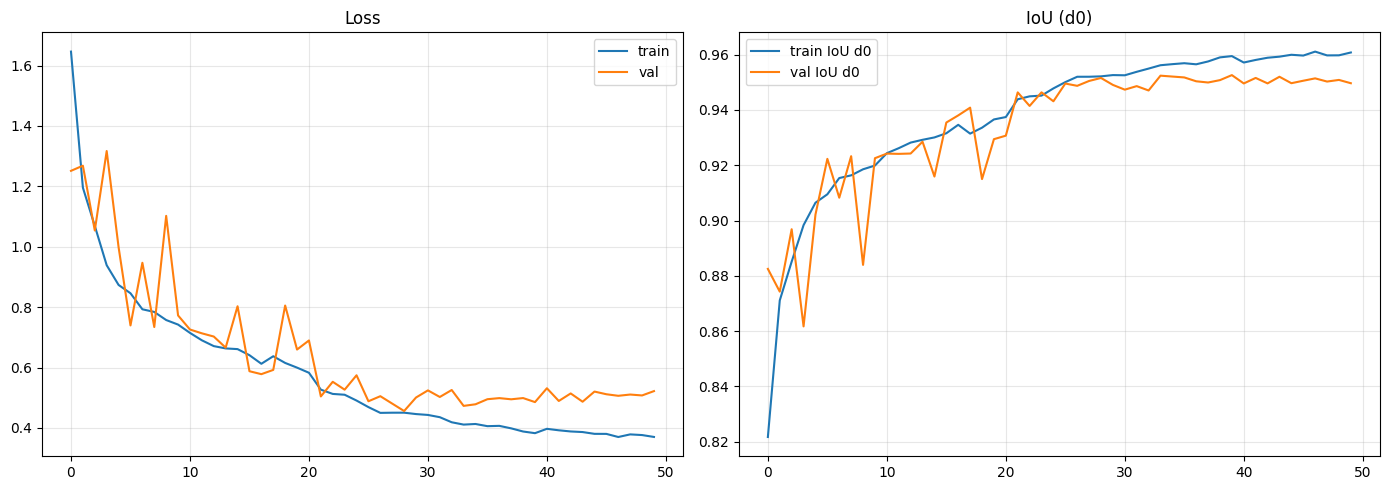

Histórico salvo em: /home/jovyan/arquivos/notebooks_jupyter_vinimw/tensorflow/Wolosky_U2Net_Sam3/Pesos_wolosky_sam3/v2_Wolosky_U2Net_Sam3_320x320/training_history_v2_Wolosky_U2Net_Sam3_320x320.png


In [17]:
# ===========================
# 5) Plot e Visualização 
# ===========================
def plot_history(h, out_dir, version):
    hist = h.history
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(hist["loss"], label="train")
    axes[0].plot(hist["val_loss"], label="val")
    axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

    key = "output_fused_iou_metric_tf"; vkey = f"val_{key}"
    if key in hist and vkey in hist:
        axes[1].plot(hist[key], label="train IoU d0")
        axes[1].plot(hist[vkey], label="val IoU d0")
    axes[1].set_title("IoU (d0)"); axes[1].legend(); axes[1].grid(True, alpha=0.3)

    p = Path(out_dir) / f"training_history_{version}.png"
    plt.tight_layout(); plt.savefig(p, dpi=150); plt.show()
    print("Histórico salvo em:", p)

plot_history(history, TrainConfig.OUT_DIR, TrainConfig.VERSION)

E0000 00:00:1765051237.502247     724 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1765051237.636472     724 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


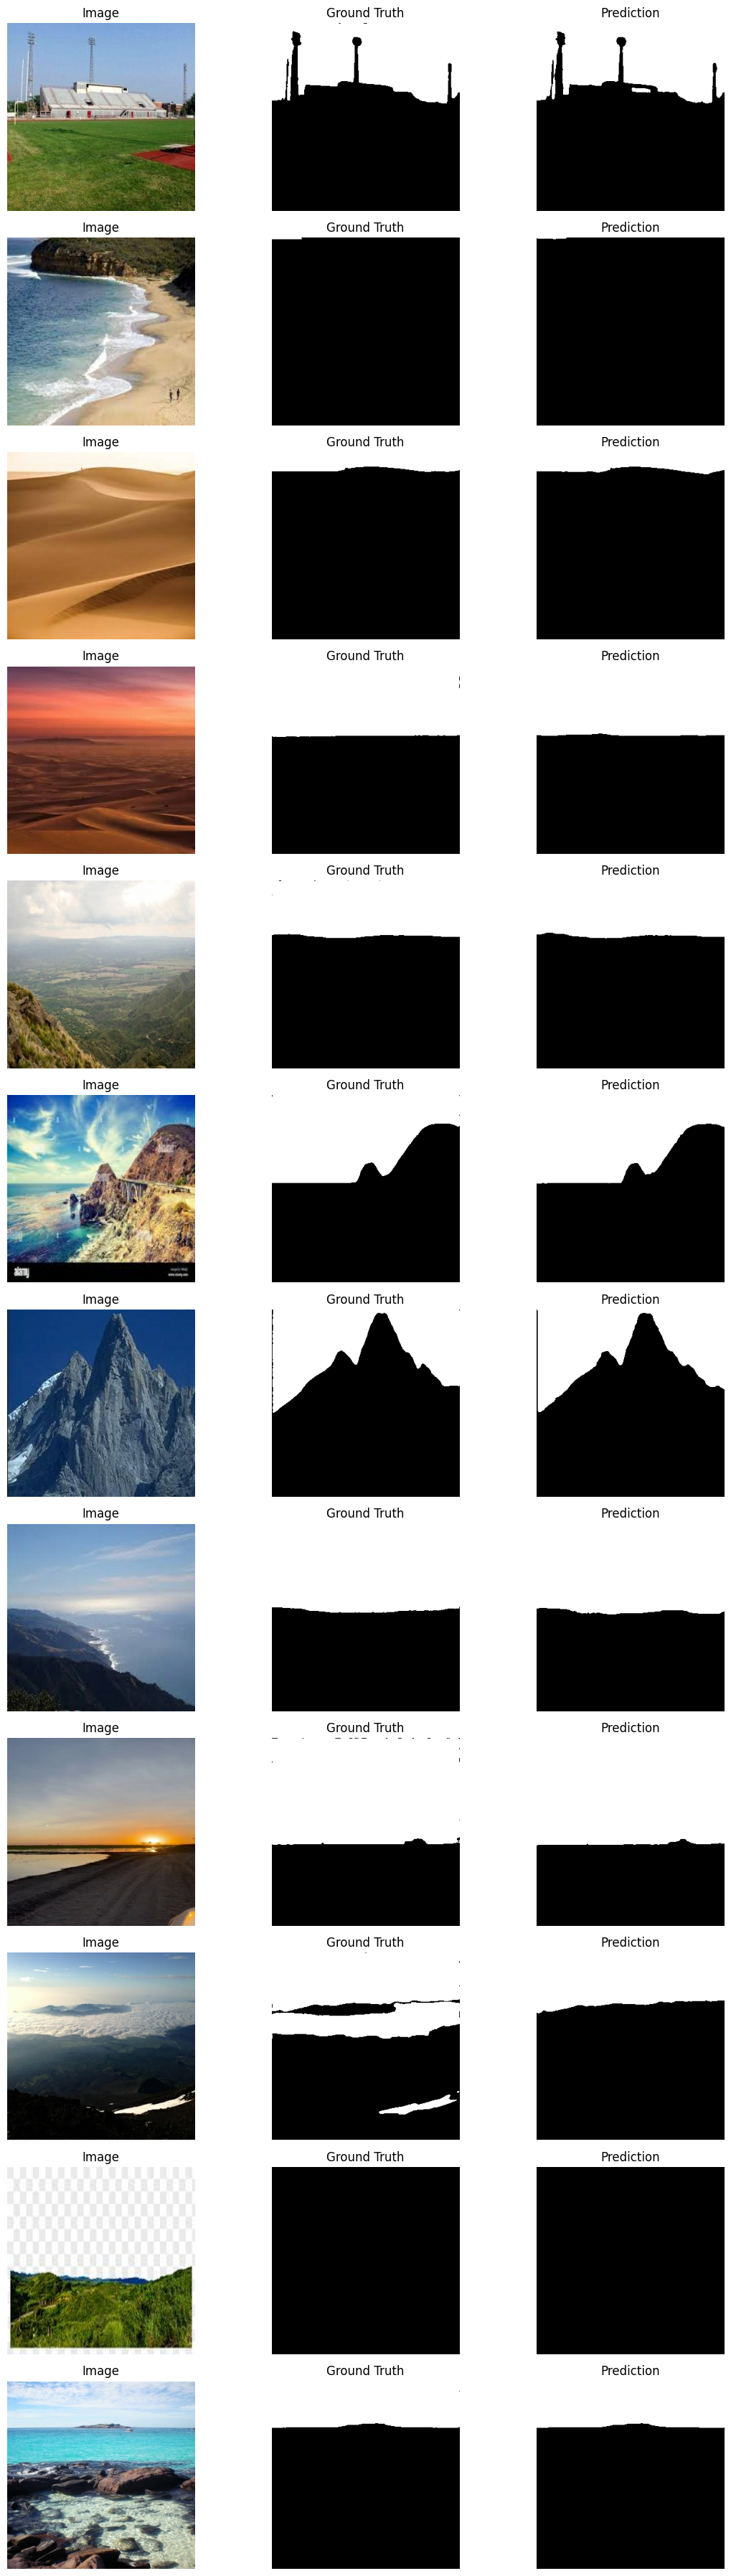

In [18]:
def visualize_predictions(model, dataset, num_images=12, save_path=None):

    
    imgs, msks = next(iter(dataset.unbatch().batch(num_images)))
    preds = model.predict(imgs, verbose=0)[0]
    preds_bin = (preds >= 0.5).astype(np.uint8)

    fig, axes = plt.subplots(num_images, 3, figsize=(12, 3*num_images))
    if num_images == 1: axes = np.expand_dims(axes, axis=0)
    
    for i in range(num_images):
        img = np.clip(imgs[i].numpy(), 0, 1)
        gt  = msks[i].numpy().squeeze()
        pr  = preds_bin[i].squeeze()
        
        axes[i,0].imshow(img); axes[i,0].set_title("Image"); axes[i,0].axis("off")
        axes[i,1].imshow(gt, cmap="gray"); axes[i,1].set_title("Ground Truth"); axes[i,1].axis("off")
        axes[i,2].imshow(pr, cmap="gray"); axes[i,2].set_title("Prediction"); axes[i,2].axis("off")
    
    plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=130)
    plt.show()
viz_path = str(Path(TrainConfig.OUT_DIR)/f"viz_val_{TrainConfig.VERSION}.png")
visualize_predictions(model, val_ds, save_path=viz_path)

In [19]:
test_ds_sup = test_ds.map(replicate_targets, num_parallel_calls=tf.data.AUTOTUNE)
results = model.evaluate(test_ds_sup, verbose=1)

test_loss = results[0]       # perda total
test_iou  = results[-1]      # IoU de d0 (output_fused)

print(f"Test IoU d0: {test_iou:.4f}")


125/129 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.4393 - output_d1_loss: 0.0854 - output_d2_loss: 0.0862 - output_d3_loss: 0.0882 - output_d4_loss: 0.0937 - output_fused_iou_metric_tf: 0.9567 - output_fused_loss: 0.0857

E0000 00:00:1765051256.264066     724 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1765051256.398233     724 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


129/129 ━━━━━━━━━━━━━━━━━━━━ 16s 121ms/step - loss: 0.4389 - output_d1_loss: 0.0853 - output_d2_loss: 0.0861 - output_d3_loss: 0.0882 - output_d4_loss: 0.0936 - output_fused_iou_metric_tf: 0.9567 - output_fused_loss: 0.0857
Test IoU d0: 0.9584


# Exportação para ONNX

In [20]:
!pip install onnxruntime onnxruntime-tools onnx -q

DEPRECATION: Loading egg at /root/anaconda3/envs/lapixdl/lib/python3.11/site-packages/paddleseg-0.0.0.dev0-py3.11.egg is deprecated. pip 25.1 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://github.com/pypa/pip/issues/12330

[notice] A new release of pip is available: 24.3.1 -> 25.3
[notice] To update, run: pip install --upgrade pip


In [21]:
# ===========================
#  Exportar para ONNX 
# 6) Modelo de inferência (apenas d0) – útil se quiser exportar só a cabeça fundida
# ===========================
from pathlib import Path
import tf2onnx
from onnxruntime.quantization import quantize_dynamic, QuantType

infer_model = keras.Model(model.input, model.outputs[0], name="LiteU2NetTF_Infer")
infer_path = Path(TrainConfig.OUT_DIR) / f"{TrainConfig.VERSION}_infer.onnx"

try:
    sig = [tf.TensorSpec(shape=(None, None, None, 3),
                         dtype=tf.float32,
                         name="input")]
    model_proto, _ = tf2onnx.convert.from_keras(
        infer_model,
        input_signature=sig,
        opset=13,
        output_path=str(infer_path),
    )
    print("ONNX (inferência) salvo em:", infer_path)
except Exception as e:
    print("Export ONNX (infer) falhou:", e)


I0000 00:00:1765051271.670248     139 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1765051271.670484     139 single_machine.cc:361] Starting new session
I0000 00:00:1765051271.687946     139 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 78764 MB memory:  -> device: 0, name: NVIDIA H100 80GB HBM3, pci bus id: 0000:52:00.0, compute capability: 9.0
I0000 00:00:1765051278.435270     139 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 78764 MB memory:  -> device: 0, name: NVIDIA H100 80GB HBM3, pci bus id: 0000:52:00.0, compute capability: 9.0
I0000 00:00:1765051280.111677     139 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1765051280.111908     139 single_machine.cc:361] Starting new session
I0000 00:00:1765051280.117517     139 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 

ONNX (inferência) salvo em: /home/jovyan/arquivos/notebooks_jupyter_vinimw/tensorflow/Wolosky_U2Net_Sam3/Pesos_wolosky_sam3/v2_Wolosky_U2Net_Sam3_320x320/v2_Wolosky_U2Net_Sam3_320x320_infer.onnx


In [22]:
OUT_DIR = Path(TrainConfig.OUT_DIR)

def quantize_to_uint8(version: str, out_dir: Path) -> Path:
    fp32_path = out_dir / f"{version}_infer.onnx"
    int8_path = out_dir / f"{version}_infer_int8_dynamic.onnx"

    if not fp32_path.exists():
        raise FileNotFoundError(fp32_path)

    quantize_dynamic(
        model_input=str(fp32_path),
        model_output=str(int8_path),
        weight_type=QuantType.QUInt8,
        op_types_to_quantize=["Conv"],
    )
    return int8_path

path = quantize_to_uint8(TrainConfig.VERSION, OUT_DIR)
print("INT8 salvo em:", path)


INT8 salvo em: /home/jovyan/arquivos/notebooks_jupyter_vinimw/tensorflow/Wolosky_U2Net_Sam3/Pesos_wolosky_sam3/v2_Wolosky_U2Net_Sam3_320x320/v2_Wolosky_U2Net_Sam3_320x320_infer_int8_dynamic.onnx


#  Tensorflow Lite

In [ ]:
# ===============================================================
# PRÉ-REQUISITOS (assumindo que já existem na sua sessão)
# ===============================================================
from pathlib import Path
import numpy as np
import tensorflow as tf
from tqdm import tqdm
import matplotlib.pyplot as plt

# Variáveis necessárias:
# model: O modelo Keras treinado com 5 saídas.
# val_ds: O tf.data.Dataset de validação.
# test_ds: O tf.data.Dataset de teste.
# test_idx: A lista de índices do conjunto de teste.
# TrainConfig: A classe de configuração.

OUT_DIR = Path(TrainConfig.OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)


# ===============================================================
# 1) Criação dos sub-modelos de inferência
# ===============================================================
# Modelo para FP32 (saída de probabilidade) - opcional, bom para baseline
infer_model_prob = tf.keras.Model(model.input, model.outputs[0], name="LiteU2Net_Infer_Prob")
print("Modelo de Probabilidade (FP32) | Saída:", infer_model_prob.output_shape)

# Modelo para INT8 (saída de logits) - ESSENCIAL para quantização correta
logits_output = model.get_layer("outconv_logits").output
infer_model_logits = tf.keras.Model(model.input, logits_output, name="LiteU2Net_Infer_Logits")
print("Modelo de Logits (INT8)        | Saída:", infer_model_logits.output_shape)


# ===============================================================
# 2) Conversão para TFLite FP32 (Baseline)
# ===============================================================
tflite_fp32_path = OUT_DIR / f"model_{TrainConfig.VERSION}_infer_fp32.tflite"
converter_fp32 = tf.lite.TFLiteConverter.from_keras_model(infer_model_prob)
converter_fp32.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model_fp32 = converter_fp32.convert()
tflite_fp32_path.write_bytes(tflite_model_fp32)
print(f"\n✔ Modelo FP32 salvo em: {tflite_fp32_path} ({tflite_fp32_path.stat().st_size / 1024:.2f} KB)")




In [ ]:
# ===============================================================
# 3) Preparação para a Quantização Full INT8
# ===============================================================
N_REP = 20  # Número robusto de amostras para calibração

def representative_dataset_gen():
    print(f"\nGerando {N_REP} amostras representativas para calibração INT8…")
    for img_tensor, _ in tqdm(val_ds.unbatch().batch(1).take(N_REP), total=N_REP, desc="Rep-dataset"):
        yield [img_tensor]


# ===============================================================
# 4) Conversão para TFLite Full INT8 (usando Logits)
# ===============================================================
tflite_int8_path = OUT_DIR / f"model_{TrainConfig.VERSION}_infer_int8_full.tflite"
converter_int8 = tf.lite.TFLiteConverter.from_keras_model(infer_model_logits)
converter_int8.optimizations = [tf.lite.Optimize.DEFAULT]
converter_int8.representative_dataset = representative_dataset_gen
converter_int8.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter_int8.inference_input_type = tf.int8
converter_int8.inference_output_type = tf.int8
converter_int8._experimental_new_quantizer = True

print("\nConvertendo para TFLite FULL-INT8 (a partir de logits)...")
tflite_model_int8 = converter_int8.convert()
tflite_int8_path.write_bytes(tflite_model_int8)
print(f"✔ Modelo Full INT8 salvo em: {tflite_int8_path} ({tflite_int8_path.stat().st_size / 1024:.2f} KB)")

In [25]:
# ===============================================================
# 5) Funções de Inferência e Avaliação Genérica
# ===============================================================
def ensure_input_shape(interpreter, image_tensor):
    shape = image_tensor.shape
    if len(shape) == 3:
        b, h, w, c = 1, int(shape[0]), int(shape[1]), int(shape[2])
    elif len(shape) == 4:
        b, h, w, c = int(shape[0]), int(shape[1]), int(shape[2]), int(shape[3])
    else:
        raise ValueError(f"shape inválido para image_tensor: {shape}")

    input_details = interpreter.get_input_details()[0]
    cur_shape = input_details["shape"]

    if cur_shape[1] != h or cur_shape[2] != w or cur_shape[3] != c or cur_shape[0] != b:
        interpreter.resize_tensor_input(input_details["index"], [b, h, w, c])
        interpreter.allocate_tensors()


def run_tflite_fp32(interpreter, image_tensor):
    ensure_input_shape(interpreter, image_tensor)
    in_det = interpreter.get_input_details()[0]
    interpreter.set_tensor(in_det["index"], image_tensor.numpy())
    interpreter.invoke()
    out_det = interpreter.get_output_details()[0]
    output_data = interpreter.get_tensor(out_det["index"])
    return (output_data >= 0.5).astype(np.uint8)

def run_tflite_int8(interpreter, image_tensor):
    ensure_input_shape(interpreter, image_tensor)
    in_det = interpreter.get_input_details()[0]
    scale_i, zero_i = in_det["quantization"]
    img_int8 = np.round(image_tensor.numpy() / scale_i + zero_i).astype(np.int8)

    interpreter.set_tensor(in_det["index"], img_int8)
    interpreter.invoke()

    out_det = interpreter.get_output_details()[0]
    scale_o, zero_o = out_det["quantization"]
    logits_f32 = (interpreter.get_tensor(out_det["index"]).astype(np.float32) - zero_o) * scale_o
    pred_bin = (tf.sigmoid(logits_f32).numpy() >= 0.5).astype(np.uint8)
    return pred_bin


def evaluate_tflite_model(model_path, inference_fn, model_type, test_dataset, num_images=8):
    interpreter = tf.lite.Interpreter(model_path=str(model_path))
    interpreter.allocate_tensors()
    print(f"\n--- Avaliando Modelo TFLite: {model_type} ---")

    inter, uni = 0, 0
    for img, mask in tqdm(test_dataset.unbatch(), desc=f"Inferindo ({model_type})", total=len(test_idx)):
        pred = inference_fn(interpreter, img[None, ...])
        gt = mask.numpy().astype(np.uint8)
        inter += np.logical_and(gt, pred).sum()
        uni += np.logical_or(gt, pred).sum()

    iou = inter / uni if uni else 0
    print(f"IoU ({model_type}) no test set: {iou:.4f}")

    fig = plt.figure(figsize=(12, num_images * 3))
    fig.suptitle(f"Visualização - Modelo {model_type} (IoU: {iou:.4f})", fontsize=16)
    for k, (img, mask) in enumerate(test_dataset.unbatch().take(num_images)):
        pred = inference_fn(interpreter, img[None, ...])
        img_vis = np.clip(img.numpy(), 0, 1)

        plt.subplot(num_images, 3, 3*k+1); plt.imshow(img_vis); plt.axis("off"); plt.title("Imagem")
        plt.subplot(num_images, 3, 3*k+2); plt.imshow(mask[..., 0], cmap="gray"); plt.axis("off"); plt.title("Ground Truth")
        plt.subplot(num_images, 3, 3*k+3); plt.imshow(pred.squeeze(), cmap="gray"); plt.axis("off"); plt.title(f"Predição {model_type}")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    viz_path = OUT_DIR / f"viz_test_TFLITE_{model_type}_{TrainConfig.VERSION}.png"
    plt.savefig(viz_path, dpi=130)
    plt.show()





/root/anaconda3/envs/lapixdl/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:451: UserWarning:     Warning: Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.



--- Avaliando Modelo TFLite: FP32 ---


Inferindo (FP32): 100%|██████████| 4107/4107 [22:52<00:00,  2.99it/s]


IoU (FP32) no test set: 0.9582


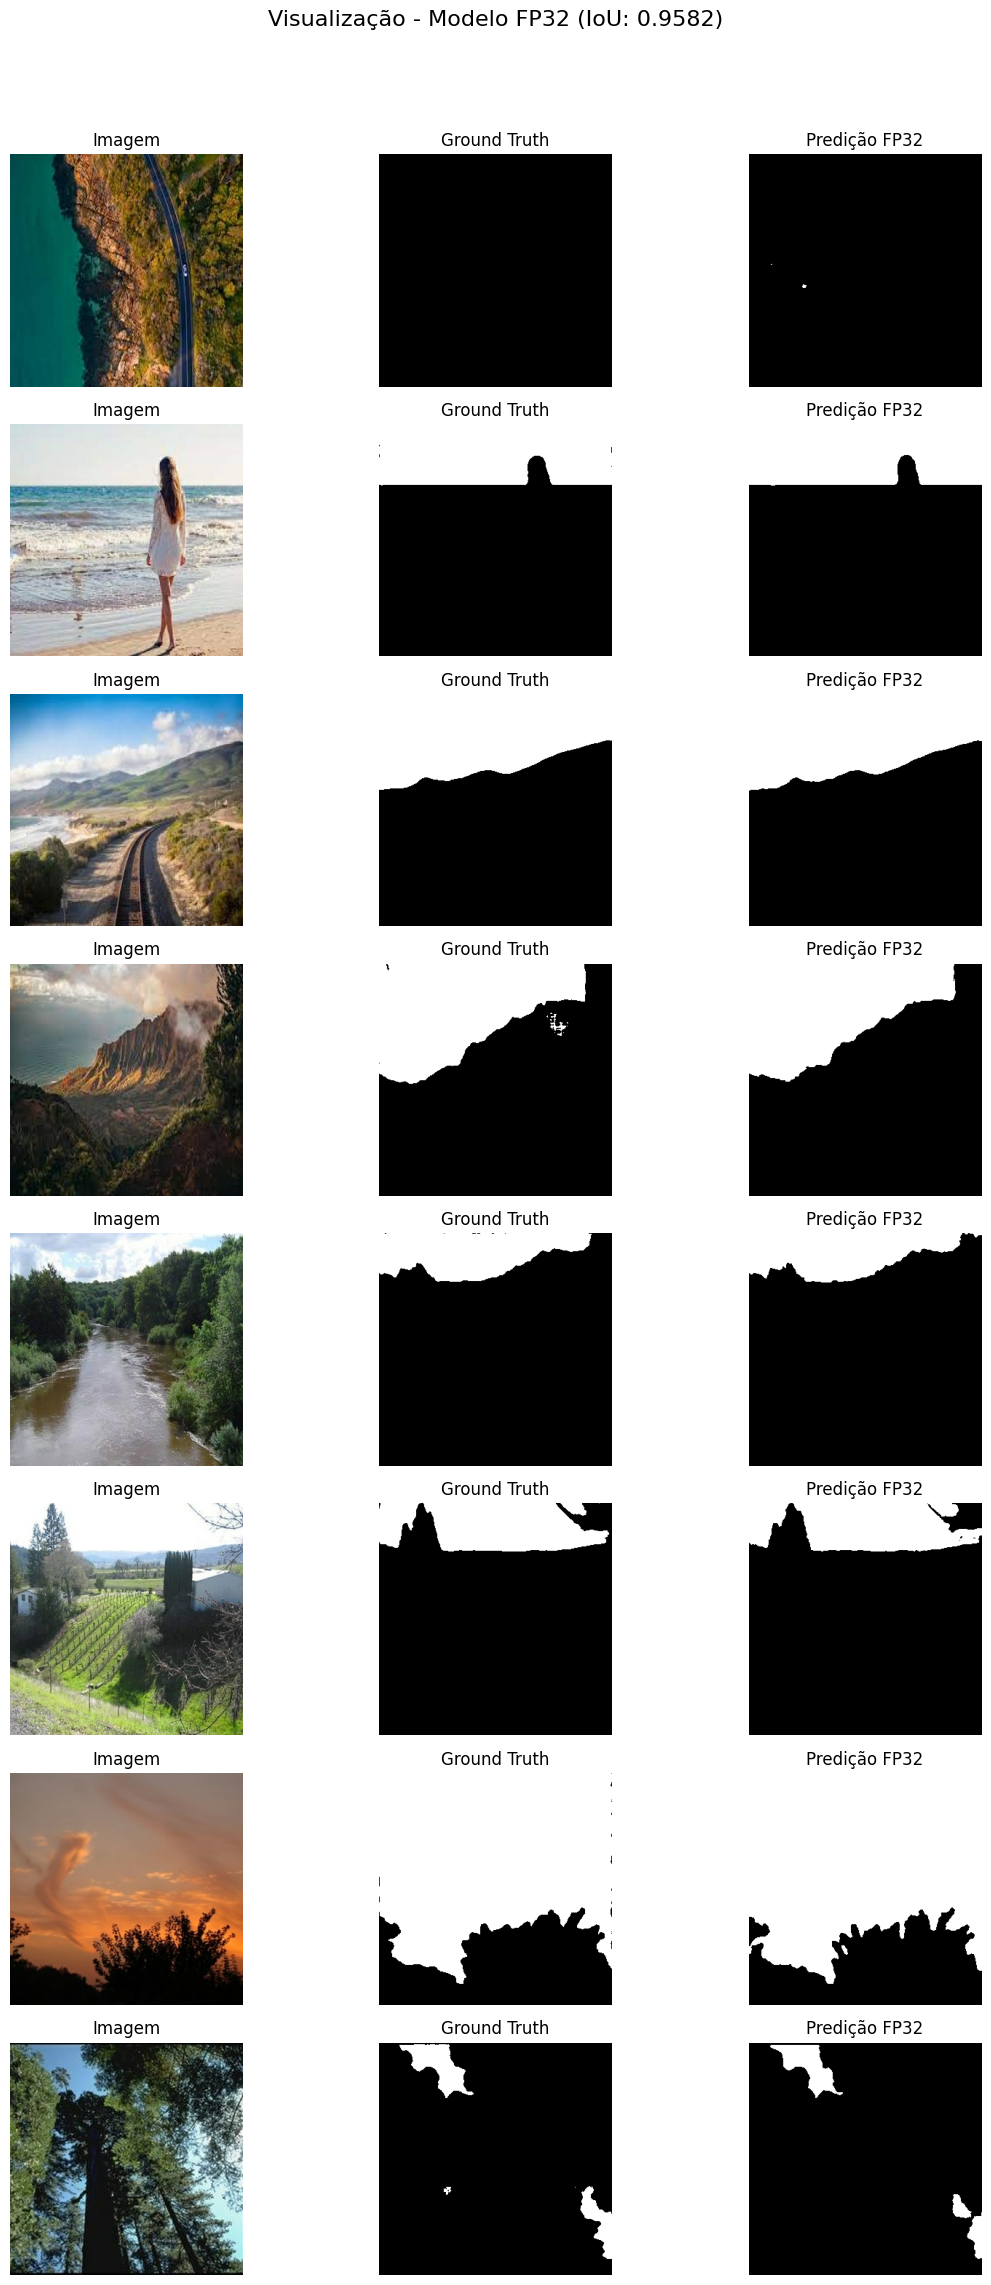

In [26]:
# ===============================================================
# 6) Execução da Avaliação Comparativa
# ===============================================================
# Avalia o modelo Float32
evaluate_tflite_model(tflite_fp32_path, run_tflite_fp32, "FP32", test_ds)


--- Avaliando Modelo TFLite: INT8 ---


Inferindo (INT8): 100%|██████████| 4107/4107 [14:02<00:00,  4.88it/s]


IoU (INT8) no test set: 0.9575


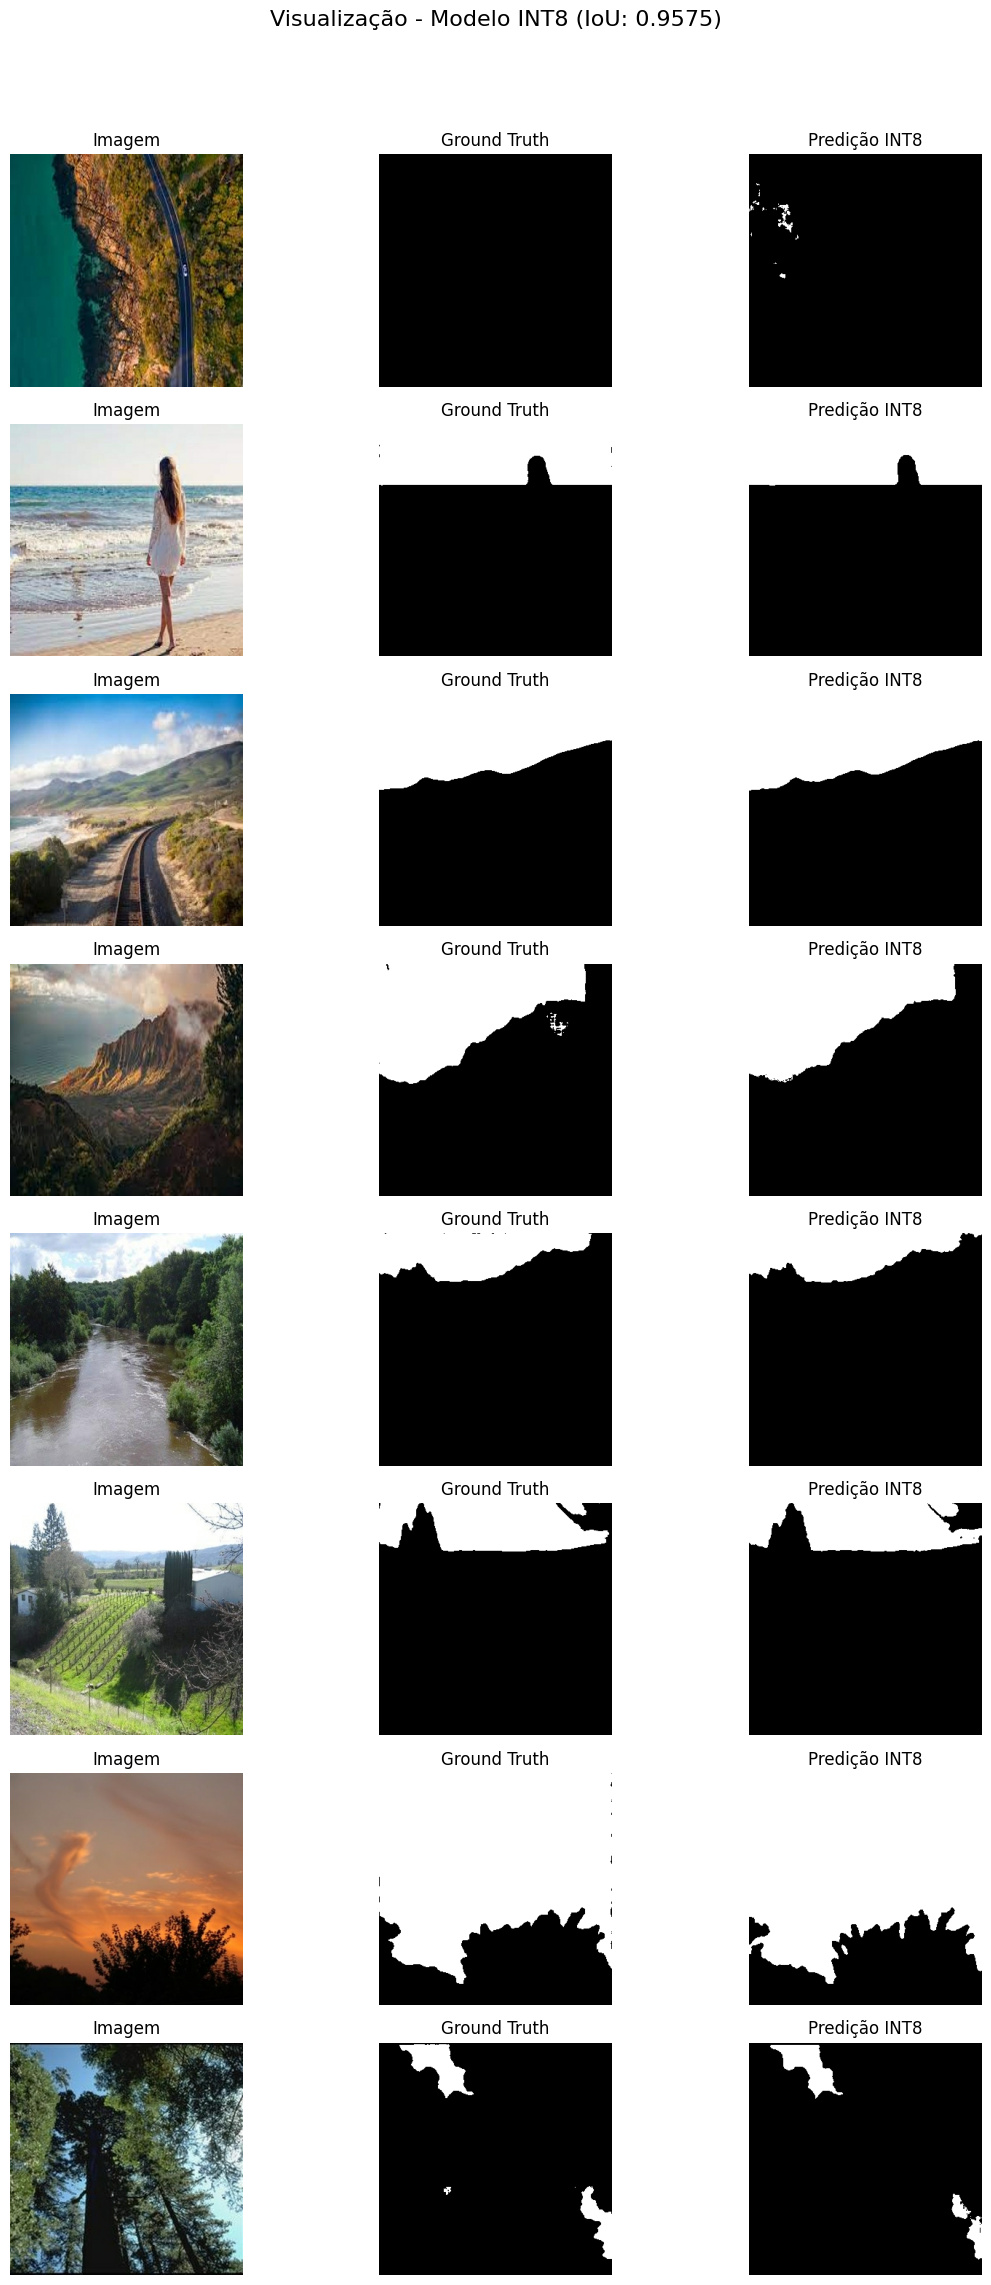

In [27]:
# Avalia o modelo Full INT8
evaluate_tflite_model(tflite_int8_path, run_tflite_int8, "INT8", test_ds)